# Sistema recomanador MovieLens

Demostració completa utilitzant les funcions modulars de `src/`.


In [87]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import (
    BiasedMatrixFactorization,
    dataset_statistics,
    evaluate_model,
    get_user_history,
    load_data,
    recommend_movies,
    temporal_train_test_split,
)

DATA_DIR = PROJECT_ROOT / "data"

## 1. Càrrega de dades


In [88]:
ratings_dataset, movies_dataset = load_data(DATA_DIR)

print("Primeres files de movies.csv:")
display(movies_dataset.head())
print("Primeres files de ratings.csv:")
display(ratings_dataset.head())

Primeres files de movies.csv:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Primeres files de ratings.csv:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 2. Estadístiques del dataset


In [89]:
statistics = dataset_statistics(ratings_dataset, movies_dataset)
display(pd.DataFrame([statistics]))

,n_users,n_movies,n_ratings,density
0,610,9742,100836,0.016968


## 3. Divisió train/test


In [90]:
ratings_train_set, ratings_test_set = temporal_train_test_split(ratings_dataset)

print(f"Mida del train: {len(ratings_train_set)} valoracions")
print(f"Mida del test: {len(ratings_test_set)} valoracions")

rating_distribution = pd.concat(
    [
        ratings_train_set["rating"].value_counts().rename("train"),
        ratings_test_set["rating"].value_counts().rename("test"),
    ],
    axis=1,
).fillna(0).astype(int).sort_index()
display(rating_distribution)

Mida del train: 80419 valoracions
Mida del test: 20417 valoracions


,train,test
rating,,
0.5,998,372
1.0,2174,637
1.5,1353,438
2.0,5985,1566
2.5,4447,1103
3.0,16203,3844
3.5,10203,2933
4.0,21561,5257
4.5,6687,1864


## 4. Entrenament

S’utilitzen els hiperparàmetres per defecte; es mostra el MSE de train a cada època.


In [91]:
model = BiasedMatrixFactorization()
train_mse_list = model.fit(ratings_train_set)

Epoch 1/20 - Train MSE: 0.9237
Epoch 2/20 - Train MSE: 0.8267
Epoch 3/20 - Train MSE: 0.7908
Epoch 4/20 - Train MSE: 0.7681
Epoch 5/20 - Train MSE: 0.7516
Epoch 6/20 - Train MSE: 0.7381
Epoch 7/20 - Train MSE: 0.7268
Epoch 8/20 - Train MSE: 0.7167
Epoch 9/20 - Train MSE: 0.7077
Epoch 10/20 - Train MSE: 0.6993
Epoch 11/20 - Train MSE: 0.6910
Epoch 12/20 - Train MSE: 0.6832
Epoch 13/20 - Train MSE: 0.6752
Epoch 14/20 - Train MSE: 0.6672
Epoch 15/20 - Train MSE: 0.6589
Epoch 16/20 - Train MSE: 0.6503
Epoch 17/20 - Train MSE: 0.6415
Epoch 18/20 - Train MSE: 0.6322
Epoch 19/20 - Train MSE: 0.6224
Epoch 20/20 - Train MSE: 0.6122


## 5. Corba d’aprenentatge


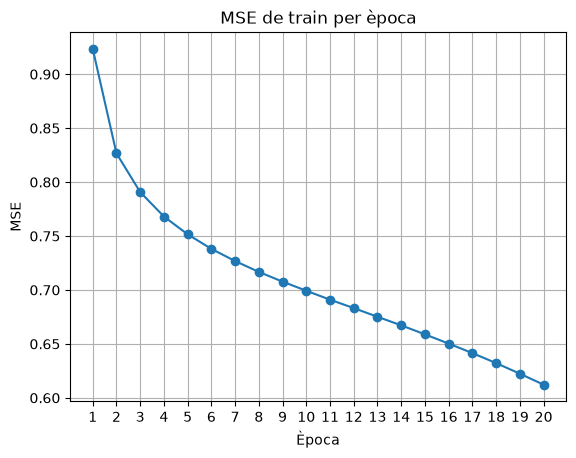

In [92]:
plt.plot(range(1, len(train_mse_list) + 1), train_mse_list, marker="o")
plt.title("MSE de train per època")
plt.xlabel("Època")
plt.ylabel("MSE")
plt.xticks(range(1, len(train_mse_list) + 1))
plt.grid(True)
plt.show()

## 6. Avaluació sobre el test


In [93]:
evaluation_metrics = evaluate_model(model, ratings_test_set, k=10)
print(f"RMSE: {evaluation_metrics['rmse']:.4f}")
print(f"MAE: {evaluation_metrics['mae']:.4f}")
print(f"NDCG@10: {evaluation_metrics['ndcg_at_k']:.4f}")
print(
    f"Prediccions vàlides: {evaluation_metrics['n_valid']} / "
    f"{len(ratings_test_set)}"
)

RMSE: 0.8894
MAE: 0.6854
NDCG@10: 0.7907
Prediccions vàlides: 18716 / 20417


## 7. Exemples de predicció

Valor real i predit per a cinc parelles del test predictibles pel model.


In [94]:
valid_test_examples = ratings_test_set.loc[
    ratings_test_set["userId"].isin(model.user2idx)
    & ratings_test_set["movieId"].isin(model.movie2idx)
].head(5).copy()
valid_test_examples["predicted_rating"] = [
    model.predict_rating(row.userId, row.movieId)
    for row in valid_test_examples.itertuples(index=False)
]
display(
    valid_test_examples[
        ["userId", "movieId", "rating", "predicted_rating"]
    ].rename(columns={"rating": "valor_real", "predicted_rating": "valor_predit"})
)

,userId,movieId,valor_real,valor_predit
0,1,2959,5.0,5.000000
1,1,2654,5.0,4.052557
2,1,2644,4.0,4.027171
3,1,1219,2.0,4.880595
4,1,1348,4.0,4.233345


## 8. Top-10 recomanacions


In [95]:
recommendation_user_ids = ratings_train_set["userId"].drop_duplicates().head(3)
for user_id in recommendation_user_ids:
    print(f"Recomanacions per a l’usuari {user_id}")
    display(
        recommend_movies(
            model, user_id, movies_dataset, ratings_train_set, n=10
        ).rename(columns={"predicted_rating": "valor_predit"})
    )

Recomanacions per a l’usuari 1


,movieId,title,genres,valor_predit
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,5
1,48516,"Departed, The (2006)",Crime|Drama|Thriller,5
2,2959,Fight Club (1999),Action|Crime|Drama|Thriller,5
3,2019,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,5
4,1199,Brazil (1985),Fantasy|Sci-Fi,5
5,912,Casablanca (1942),Drama|Romance,5
6,1250,"Bridge on the River Kwai, The (1957)",Adventure|Drama|War,5
7,898,"Philadelphia Story, The (1940)",Comedy|Drama|Romance,5
8,527,Schindler's List (1993),Drama|War,5
9,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,5


Recomanacions per a l’usuari 2


,movieId,title,genres,valor_predit
0,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.434999
1,1204,Lawrence of Arabia (1962),Adventure|Drama|War,4.414401
2,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.389091
3,858,"Godfather, The (1972)",Crime|Drama,4.384246
4,1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,4.331410
5,1136,Monty Python and the Holy Grail (1975),Adventure|Comedy|Fantasy,4.319738
6,1201,"Good, the Bad and the Ugly, The (Buono, il bru...",Action|Adventure|Western,4.300191
7,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.290982
8,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.275054
9,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.272855


Recomanacions per a l’usuari 3


,movieId,title,genres,valor_predit
0,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,3.894546
1,912,Casablanca (1942),Drama|Romance,3.884124
2,1208,Apocalypse Now (1979),Action|Drama|War,3.857206
3,930,Notorious (1946),Film-Noir|Romance|Thriller,3.854924
4,4973,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",Comedy|Romance,3.852641
5,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,3.844430
6,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,3.831415
7,1204,Lawrence of Arabia (1962),Adventure|Drama|War,3.820736
8,6711,Lost in Translation (2003),Comedy|Drama|Romance,3.818003
9,1201,"Good, the Bad and the Ugly, The (Buono, il bru...",Action|Adventure|Western,3.801281


## 9. Historial d’un usuari


In [96]:
history_user_id = ratings_train_set["userId"].iloc[0]
print(f"Historial de l’usuari {history_user_id}")
display(get_user_history(history_user_id, ratings_train_set, movies_dataset))

Historial de l’usuari 1


,movieId,title,genres,rating
0,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,5.0
69,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,5.0
130,362,"Jungle Book, The (1994)",Adventure|Children|Romance,5.0
124,2115,Indiana Jones and the Temple of Doom (1984),Action|Adventure|Fantasy,5.0
120,2987,Who Framed Roger Rabbit? (1988),Adventure|Animation|Children|Comedy|Crime|Fant...,5.0
...,...,...,...,...
102,316,Stargate (1994),Action|Adventure|Sci-Fi,3.0
20,3243,Encino Man (1992),Comedy,3.0
179,2389,Psycho (1998),Crime|Horror|Thriller,2.0
131,2617,"Mummy, The (1999)",Action|Adventure|Comedy|Fantasy|Horror|Thriller,2.0
